Cell 0 — Imports

In [14]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import json
from datetime import datetime


Cell 1 — Step 1 helpers (global state)

In [15]:
def simulate_global_state(T=20000, D=256, seed=123, mu=-1.5, sigma=0.3, sigma_drift=0.001):
    rng = np.random.default_rng(seed)
    alpha = rng.normal(mu, sigma, size=D)
    beta  = rng.normal(mu, sigma, size=D)
    eps = np.zeros(D)
    X = np.zeros((T, D), dtype=np.int8)
    X[0] = rng.binomial(1, 0.5, size=D)
    for t in range(1, T):
        eps += rng.normal(0, sigma_drift, size=D)
        p = 1 / (1 + np.exp(-(alpha + eps)))
        q = 1 / (1 + np.exp(-(beta  + eps)))
        X[t] = rng.binomial(1, np.where(X[t-1]==0, p, 1-q))
    return X


Cell 2 — Step 2 helpers (nodes + signals)

In [16]:
def construct_nodes(D=256, K=40, subset_size=25, overlap_target=5, seed=123):
    rng = np.random.default_rng(seed)
    subsets = [set(rng.choice(D, subset_size, replace=False))]
    for _ in range(1, K):
        base_subset = subsets[rng.integers(len(subsets))]
        base = rng.choice(list(base_subset), overlap_target, replace=False)
        rest = rng.choice(list(set(range(D)) - set(base)), subset_size - overlap_target, replace=False)
        subsets.append(set(base) | set(rest))
    return subsets

def compute_node_signals(X, subsets):
    Z = np.zeros((X.shape[0], len(subsets)), dtype=np.float32)
    for k, S in enumerate(subsets):
        Z[:, k] = X[:, list(S)].mean(axis=1)
    return Z


Cell 3 — Step 5 destruction helper (bit-flip)

In [ ]:
def destroy_bitflip_X(X, delta, seed=999):
    rng = np.random.default_rng(seed)
    flips = rng.random(X.shape) < delta
    Xd = X.copy()z
    Xd[flips] = 1 - Xd[flips]
    return Xd


Cell 4 — Step 4 dataset used for evaluation (masked windows)

In [18]:
class MaskedWindowDataset(Dataset):
    def __init__(self, Z, window=128, mask_ratio=0.15, seed=2):
        rng = np.random.default_rng(seed)
        T, K = Z.shape
        self.Z = Z.astype(np.float32)
        self.window = window
        self.N = T - window
        self.masks = rng.random((self.N, window, K)) < mask_ratio

    def __len__(self):
        return self.N

    def __getitem__(self, idx):
        x = self.Z[idx:idx+self.window].copy()
        m = self.masks[idx]
        y = x.copy()
        x[m] = 0.0
        return torch.from_numpy(x), torch.from_numpy(m), torch.from_numpy(y)


Cell 5 — Model class (must match training)

In [19]:
class MaskedTimeTransformer(nn.Module):
    def __init__(self, K, window=128, d_model=128, nhead=4, num_layers=3, dim_ff=256, dropout=0.1):
        super().__init__()
        self.in_proj = nn.Linear(K, d_model)
        self.pos_emb = nn.Parameter(torch.randn(window, d_model) * 0.02)

        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.out_proj = nn.Linear(d_model, K)

    def forward(self, x):
        B, L, _ = x.shape
        h = self.in_proj(x) + self.pos_emb[:L].unsqueeze(0)
        h = self.encoder(h)
        return self.out_proj(h)


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from datetime import datetime

# -----------------------------
# 1) Set the new window
# -----------------------------
window = 8
mask_ratio = 0.15

# -----------------------------
# 2) Rebuild datasets/loaders (CLEAN data)
#    Use the same Z you used for run1_clean_model.pt
# -----------------------------
# Assumes you already have:
#   Z_train, Z_val   (or a single Z and a split index)
#   MaskedWindowDataset available
#
# If in your notebook you do something like:
#   Z = compute_node_signals(X, subsets)
#   split = ...
# then do:
#   Z_train = Z[:split]
#   Z_val   = Z[split-window:]  # keep -window for first val window
# --------------------------------
# Recreate clean signal and split
# --------------------------------

# Clean (no noise) signal
Zd_clean = compute_node_signals(X, subsets)

# Same split logic you used before
split = int(0.8 * len(Zd_clean))

# IMPORTANT: for windowed validation, include -window offset
Z_train = Zd_clean[:split]
Z_val   = Zd_clean[split - window:]


train_ds = MaskedWindowDataset(Z_train, window=window, mask_ratio=mask_ratio, seed=1)
val_ds   = MaskedWindowDataset(Z_val,   window=window, mask_ratio=mask_ratio, seed=2)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False)

# -----------------------------
# 3) Build model (same K, new window)
# -----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MaskedTimeTransformer(K=K, window=window).to(device)

# -----------------------------
# 4) Optim + loss
# -----------------------------
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)
criterion = nn.CrossEntropyLoss()  # typical if your model outputs logits over K bins

# -----------------------------
# 5) Train loop
# -----------------------------
# Forward
def run_epoch(model, loader, train: bool):
    model.train(train)

    total_loss = 0.0
    total_count = 0

    for batch in loader:
        x_in, mask, y_true = batch  # <- matches your printed batch structure

        x_in   = x_in.to(device)     # [B,W,40] float
        mask   = mask.to(device)     # [B,W,40] bool
        y_true = y_true.to(device)   # [B,W,40] float

        y_pred = model(x_in)         # SHOULD be [B,W,40]

        if y_pred.shape != y_true.shape:
            raise RuntimeError(f"Model output {tuple(y_pred.shape)} != target {tuple(y_true.shape)}")

        # Masked loss only where mask == True
        diff2 = (y_pred - y_true) ** 2
        loss_sum = diff2[mask].sum()
        count = mask.sum().clamp(min=1)
        loss = loss_sum / count

        if train:
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        total_loss += loss.item() * int(count.item())
        total_count += int(count.item())

    return total_loss / max(total_count, 1)

# Train
epochs = 20
best_val = float("inf")
save_path = "run_window8_clean_model.pt"

for ep in range(1, epochs + 1):
    tr_loss = run_epoch(model, train_loader, train=True)
    va_loss = run_epoch(model, val_loader, train=False)

    print(f"epoch {ep:02d} | train loss {tr_loss:.4f} | val loss {va_loss:.4f}")


    if va_loss < best_val:
        best_val = va_loss
        torch.save(model.state_dict(), save_path)

print("saved best:", save_path, "best_val:", best_val)

# -----------------------------
# 6) Load later (no mismatch now)
# -----------------------------
model = MaskedTimeTransformer(K=K, window=window).to(device)
model.load_state_dict(torch.load(save_path, map_location=device))
model.eval()
print("loaded:", save_path, "on", device)

epoch 01 | train loss 0.0247 | val loss 0.0103
epoch 01 | train loss 0.0247 | val loss 0.0103
epoch 02 | train loss 0.0131 | val loss 0.0100
epoch 02 | train loss 0.0131 | val loss 0.0100
epoch 03 | train loss 0.0111 | val loss 0.0097
epoch 03 | train loss 0.0111 | val loss 0.0097
epoch 04 | train loss 0.0103 | val loss 0.0095
epoch 04 | train loss 0.0103 | val loss 0.0095
epoch 05 | train loss 0.0098 | val loss 0.0091
epoch 05 | train loss 0.0098 | val loss 0.0091
epoch 06 | train loss 0.0094 | val loss 0.0090
epoch 06 | train loss 0.0094 | val loss 0.0090
epoch 07 | train loss 0.0092 | val loss 0.0088
epoch 07 | train loss 0.0092 | val loss 0.0088
epoch 08 | train loss 0.0090 | val loss 0.0086
epoch 08 | train loss 0.0090 | val loss 0.0086
epoch 09 | train loss 0.0089 | val loss 0.0086
epoch 09 | train loss 0.0089 | val loss 0.0086
epoch 10 | train loss 0.0087 | val loss 0.0086
epoch 10 | train loss 0.0087 | val loss 0.0086
epoch 11 | train loss 0.0086 | val loss 0.0084
epoch 11 | tr

C:\Users\user\AppData\Local\Temp\ipykernel_40888\3043968813.py:120: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(save_path, map_location=de

In [26]:
batch = next(iter(train_loader))
print("batch type:", type(batch))
print("len(batch):", len(batch))
for i, t in enumerate(batch):
    print(i, "shape:", getattr(t, "shape", None), "dtype:", getattr(t, "dtype", None))

batch type: <class 'list'>
len(batch): 3
0 shape: torch.Size([64, 8, 40]) dtype: torch.float32
1 shape: torch.Size([64, 8, 40]) dtype: torch.bool
2 shape: torch.Size([64, 8, 40]) dtype: torch.float32


Cell 6 — Load model weights

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

K = 40
window = 8  #128
mask_ratio = 0.15

model = MaskedTimeTransformer(K=K, window=window).to(device)
model.load_state_dict(torch.load("run1_window8_clean_model.pt", map_location=device))
model.eval()

print("loaded on", device)


C:\Users\user\AppData\Local\Temp\ipykernel_40888\3411237260.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("run1_clean_model.pt", map_l

RuntimeError: Error(s) in loading state_dict for MaskedTimeTransformer:
	size mismatch for pos_emb: copying a param with shape torch.Size([128, 128]) from checkpoint, the shape in current model is torch.Size([8, 128]).

Cell 7 — Step 7 info-theory utilities + collectors + baseline

In [28]:
def discretize(x, bins):
    return np.digitize(x, bins) - 1

def entropy_from_counts(counts):
    p = counts / counts.sum()
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

def mutual_information(x, y):
    xy = np.stack([x, y], axis=1)
    _, cxy = np.unique(xy, axis=0, return_counts=True)
    _, cx = np.unique(x, return_counts=True)
    _, cy = np.unique(y, return_counts=True)
    Hx = entropy_from_counts(cx)
    Hy = entropy_from_counts(cy)
    Hxy = entropy_from_counts(cxy)
    return Hx + Hy - Hxy

def H_from_samples(x):
    _, cx = np.unique(x, return_counts=True)
    return entropy_from_counts(cx)

@torch.no_grad()
def collect_masked_predictions(model, loader, device):
    model.eval()
    z_true, z_pred = [], []
    for xb, mb, yb in loader:
        xb = xb.to(device).float()
        m = mb.numpy().astype(bool)
        y = yb.numpy().astype(np.float32)
        yhat = model(xb).cpu().numpy().astype(np.float32)
        z_true.append(y[m])
        z_pred.append(yhat[m])
    return np.concatenate(z_true), np.concatenate(z_pred)

def baseline_predict_window_node_mean(x_masked_np):
    node_means = x_masked_np.mean(axis=1, keepdims=True)  # (B,1,K)
    return np.repeat(node_means, x_masked_np.shape[1], axis=1)

def collect_baseline_window_predictions(val_loader):
    z_true, z_pred = [], []
    for xb, mb, yb in val_loader:
        x = xb.numpy().astype(np.float32)
        m = mb.numpy().astype(bool)
        y = yb.numpy().astype(np.float32)
        yhat = baseline_predict_window_node_mean(x)
        z_true.append(y[m])
        z_pred.append(yhat[m])
    return np.concatenate(z_true), np.concatenate(z_pred)


Cell 8 — Build base data once (for Step 7 sweeps)

In [29]:
T = 20000
seed_world = 123
seed_nodes = 123

X = simulate_global_state(T=T, seed=seed_world)
subsets = construct_nodes(K=K, seed=seed_nodes)
Z = compute_node_signals(X, subsets)
split = int(0.8 * Z.shape[0])

bins = np.linspace(0, 1, 21)


Cell 9 — Step 7 delta sweep (you edit deltas here)

In [30]:
# noise from 0.0 to 0.8 inclusive, step 0.1
noises = np.round(np.arange(0.0, 0.81, 0.1), 2)

def plnp_entropy_from_samples(x):
    # computes -sum p ln p (natural log) from discrete samples
    _, counts = np.unique(x, return_counts=True)
    p = counts / counts.sum()
    p = p[p > 0]
    return float(-np.sum(p * np.log(p)))  # nats

results = []
for noise in noises:
    Xd = destroy_bitflip_X(X, noise, seed=999)
    Zd = compute_node_signals(Xd, subsets)

    Z_val_d = Zd[split - window:]
    val_ds = MaskedWindowDataset(Z_val_d, window=window, mask_ratio=mask_ratio, seed=2)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

    zt_tf, zp_tf = collect_masked_predictions(model, val_loader, device)
    zt_tf_d = discretize(zt_tf, bins)
    zp_tf_d = discretize(zp_tf, bins)

    H_true_bits = H_from_samples(zt_tf_d)                 # bits (log2)
    H_true_plnp = plnp_entropy_from_samples(zt_tf_d)      # nats (ln)

    MI_tf = mutual_information(zt_tf_d, zp_tf_d)
    R_tf = MI_tf / H_true_bits if H_true_bits > 1e-12 else 0.0

    zt_b, zp_b = collect_baseline_window_predictions(val_loader)
    zt_b_d = discretize(zt_b, bins)
    zp_b_d = discretize(zp_b, bins)

    MI_b = mutual_information(zt_b_d, zp_b_d)
    R_b = MI_b / H_true_bits if H_true_bits > 1e-12 else 0.0

    H_pred_tf_plnp = plnp_entropy_from_samples(zp_tf_d)
    H_pred_b_plnp  = plnp_entropy_from_samples(zp_b_d)

    results.append({
        "noise": float(noise),
        "H_true_bits": float(H_true_bits),
        "H_true_plnp": float(H_true_plnp),
        "MI_transformer": float(MI_tf),
        "R_transformer": float(R_tf),
        "MI_baseline_window": float(MI_b),
        "R_baseline_window": float(R_b),
        "H_pred_tf_plnp": float(H_pred_tf_plnp),
        "H_pred_b_plnp": float(H_pred_b_plnp),
    })

results[:2], results[-1]

([{'noise': 0.0,
   'H_true_bits': 2.9846213187390678,
   'H_true_plnp': 2.0687818521230907,
   'MI_transformer': 0.16426703404078769,
   'R_transformer': 0.05503781434831627,
   'MI_baseline_window': 0.08726015331122738,
   'R_baseline_window': 0.02923659117602656,
   'H_pred_tf_plnp': 1.437848012985383,
   'H_pred_b_plnp': 1.8865099990289405},
  {'noise': 0.1,
   'H_true_bits': 2.981241458795162,
   'H_true_plnp': 2.066439111732285,
   'MI_transformer': 0.11283366387454219,
   'R_transformer': 0.037847878286297126,
   'MI_baseline_window': 0.03875122106185014,
   'R_baseline_window': 0.012998350384376797,
   'H_pred_tf_plnp': 1.3895973077618324,
   'H_pred_b_plnp': 1.8311403438785887}],
 {'noise': 0.8,
  'H_true_bits': 2.983230494859685,
  'H_true_plnp': 2.0678178064724406,
  'MI_transformer': 0.0627247884799802,
  'R_transformer': 0.02102579354430018,
  'MI_baseline_window': 0.015319736104135728,
  'R_baseline_window': 0.005135284092373253,
  'H_pred_tf_plnp': 1.3229276347269434,
  

Cell 10 — Plot + save (end of notebook)

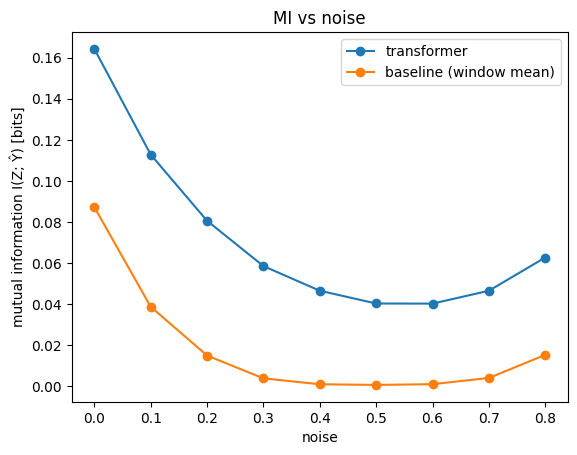

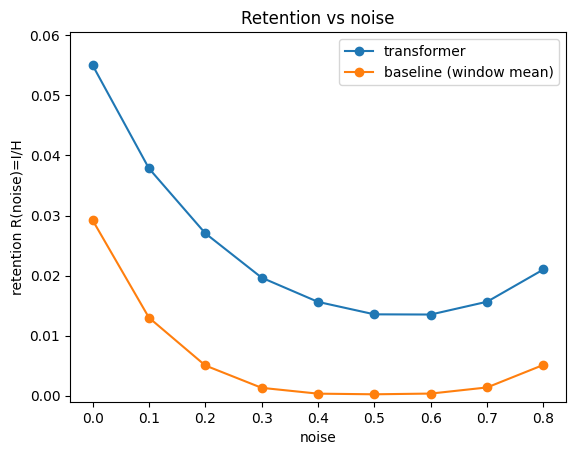

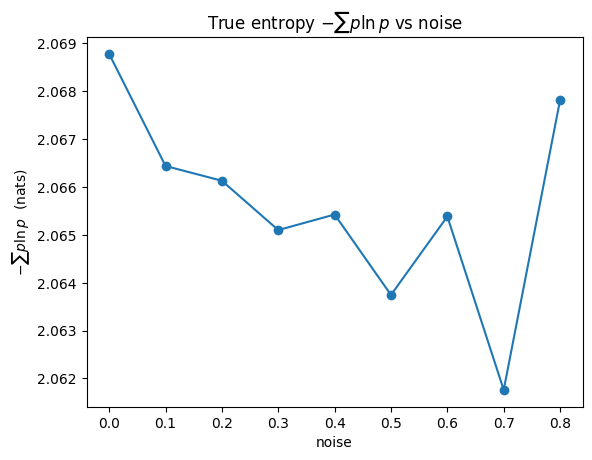

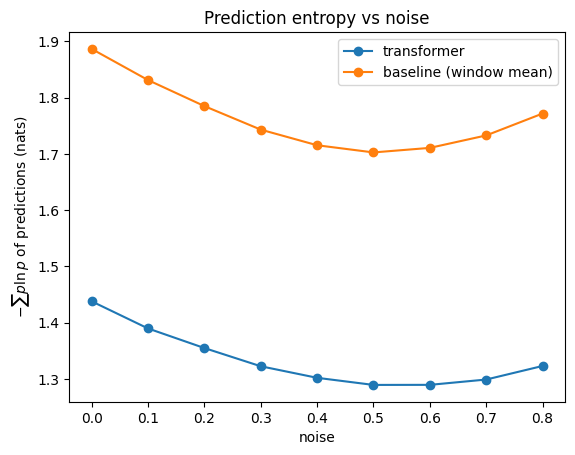

saved: step7_run_20260224_105155.json


In [31]:
n = [r["noise"] for r in results]

# existing curves (kept)
mi_tf = [r["MI_transformer"] for r in results]
mi_b  = [r["MI_baseline_window"] for r in results]
r_tf  = [r["R_transformer"] for r in results]
r_b   = [r["R_baseline_window"] for r in results]

# NEW: -sum p ln p curve
h_plnp = [r["H_true_plnp"] for r in results]

h_pred_tf = [r["H_pred_tf_plnp"] for r in results]
h_pred_b  = [r["H_pred_b_plnp"] for r in results]

plt.figure()
plt.plot(n, mi_tf, marker="o")
plt.plot(n, mi_b, marker="o")
plt.xlabel("noise")
plt.ylabel("mutual information I(Z; Ŷ) [bits]")
plt.title("MI vs noise")
plt.legend(["transformer", "baseline (window mean)"])
plt.show()

plt.figure()
plt.plot(n, r_tf, marker="o")
plt.plot(n, r_b, marker="o")
plt.xlabel("noise")
plt.ylabel("retention R(noise)=I/H")
plt.title("Retention vs noise")
plt.legend(["transformer", "baseline (window mean)"])
plt.ylim(-0.001, max(r_tf)*1.1)
plt.show()

# NEW plot: -p ln p vs noise
plt.figure()
plt.plot(n, h_plnp, marker="o")
plt.xlabel("noise")
plt.ylabel(r"$-\sum p \ln p$  (nats)")
plt.title(r"True entropy $-\sum p\ln p$ vs noise")
plt.show()


plt.figure()
plt.plot(n, h_pred_tf, marker="o")
plt.plot(n, h_pred_b, marker="o")
plt.xlabel("noise")
plt.ylabel(r"$-\sum p \ln p$ of predictions (nats)")
plt.title(r"Prediction entropy vs noise")
plt.legend(["transformer", "baseline (window mean)"])
plt.show()

run = {
    "config": {
        "T": T,
        "K": K,
        "window": window,
        "mask_ratio": mask_ratio,
        "bins": bins.tolist(),
        "noises": n,
        "destruction": "bitflip_X",
        "seed_world": seed_world,
        "seed_nodes": seed_nodes,
        "seed_destroy": 999,
        "model_weights": "run1_clean_model.pt",
        "model_hparams": {
            "d_model": 128, "nhead": 4, "num_layers": 3, "dim_ff": 256, "dropout": 0.1
        }
    },
    "results": results
}

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
fname = f"step7_run_{stamp}.json"
with open(fname, "w") as f:
    json.dump(run, f, indent=2)
print("saved:", fname)